# 02c: Feature Ablation

**Задача ноутбука:** выявить группы признаков, которые подозрительно завышают метрики и могут оказаться утечкой.

**Причина:** `research/02b` показал PR-AUC = 0.98 на holdout, причём в топ признаков по gain попали *`*_err` и MES-статистики*, в следствие чего выходит гипотеза: **ошибки физических параметров являются proxy качества фитинга транзита, а качесво фитинга - прямой вход Robovetter - модели NASA, выдающей `koi_disposition` - прямая утечка.**

**Суть проверки:** обучить LGBM с идентичной CV на 5 наборах признаков и сравнить метрики. Разниа между наборами покажет вклад каждой группы. Аномалии зафиксировать и сделать выводы.

### Импорты и пути

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, f1_score, brier_score_loss,
)

DATA_DIR = Path("../../data")
FINAL_DIR = DATA_DIR / "physical_signs_final"
ABLATION_DIR = FINAL_DIR / "ablation"
ABLATION_DIR.mkdir(parents=True, exist_ok=True)

### Загрузка и восстановление сплитов

In [4]:
koi = pd.read_csv(FINAL_DIR / "koi_clean.csv")
y = koi["label"].astype(int)
groups = koi["kepid"]
X = koi.drop(columns=["label", "kepid", "kepoi_name"])

train_idx = pd.read_csv(FINAL_DIR / "holdout_train_idx.csv")["idx"].values
test_idx = pd.read_csv(FINAL_DIR / "holdout_test_idx.csv")["idx"].values

X_train = X.iloc[train_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

cv_folds = pd.read_csv(FINAL_DIR / "cv_folds.csv")
folds = {}
for fold_id, d in cv_folds.groupby("fold"):
    folds[fold_id] = (
        d.loc[d["part"] == "train", "train_local_idx"].values,
        d.loc[d["part"] == "val", "train_local_idx"].values,
    )

print(f"X: {X.shape} | train: {len(X_train)} | test: {len(X_test)}")
print(f"Folds: {sorted(folds.keys())}")

X: (7327, 53) | train: 5862 | test: 1465
Folds: [0, 1, 2, 3, 4]


## Определение наборов признаков

| Набор | Что убирается | Гипотеза |
|---|---|---|
| `all` | ничего | baseline; ожидаем ~0.98 PR-AUC |
| `no_err` | все `*_err1`, `*_err2` | proxy качества фита → большая часть утечки |
| `no_mes` | `koi_max_mult_ev`, `koi_max_sngle_ev` | MES близок к решению веттера |
| `no_err_no_mes` | оба | композитный честный набор |
| `core_physics` | всё, кроме «чистой» физики | максимально строгий тест |

**Что остаётся в core_physics:** `koi_period`, `koi_duration`, `koi_depth`, `koi_prad`, `koi_teq`, `koi_insol`, `koi_ror`, `koi_dor`, `koi_impact`, `koi_steff`, `koi_slogg`, `koi_srad`, `koi_smass`, `koi_smet`, `koi_sage`, `koi_srho`, `koi_kepmag`, `koi_model_snr`, `koi_num_transits`, `koi_count`. Это параметры, которые астрофизик мог бы измерить независимо от веттинга.

In [5]:
all_cols = list(X.columns)

no_err_cols = [c for c in all_cols if "_err" not in c]
no_mes_cols = [c for c in all_cols if c not in ("koi_max_mult_ev", "koi_max_sngle_ev")]
no_err_no_mes_cols = [
    c for c in all_cols
    if "_err" not in c and c not in ("koi_max_mult_ev", "koi_max_sngle_ev")
]

core_physics_candidates = [
    "koi_period", "koi_duration", "koi_depth",
    "koi_prad", "koi_teq", "koi_insol",
    "koi_ror", "koi_dor", "koi_impact",
    "koi_steff", "koi_slogg", "koi_srad",
    "koi_smass", "koi_smet", "koi_sage", "koi_srho",
    "koi_kepmag", "koi_model_snr",
    "koi_num_transits", "koi_count",
]
core_physics_cols = [c for c in core_physics_candidates if c in X.columns]

feature_sets = {
    "all": all_cols,
    "no_err": no_err_cols,
    "no_mes": no_mes_cols,
    "no_err_no_mes": no_err_no_mes_cols,
    "core_physics": core_physics_cols,
}

for name, cols in feature_sets.items():
    print(f"{name:20s}: {len(cols):3d} features")

all                 :  53 features
no_err              :  23 features
no_mes              :  51 features
no_err_no_mes       :  21 features
core_physics        :  19 features


### Helper для обучения

In [6]:
LGB_PARAMS = dict(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight="balanced",
    random_state=1,
    n_jobs=-1,
    verbose=-1,
)

def train_and_eval(name, cols):
    """Train LGBM with 5-fold CV on `cols`, return dict with metrics + preds + model."""
    Xtr = X_train[cols]
    Xte = X_test[cols]

    oof = np.zeros(len(Xtr))
    best_iters = []

    for fold_id, (tr, va) in folds.items():
        model = lgb.LGBMClassifier(**LGB_PARAMS)
        model.fit(
            Xtr.iloc[tr], y_train.iloc[tr],
            eval_set=[(Xtr.iloc[va], y_train.iloc[va])],
            eval_metric="binary_logloss",
            callbacks=[lgb.early_stopping(100, verbose=False)],
        )
        oof[va] = model.predict_proba(Xtr.iloc[va])[:, 1]
        best_iters.append(model.best_iteration_)

    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1s = 2 * prec * rec / (prec + rec + 1e-10)
    best_f1_idx = int(np.argmax(f1s[:-1]))
    best_thr = float(thr[best_f1_idx])

    n_final = int(np.median(best_iters))
    final = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": n_final})
    final.fit(Xtr, y_train)
    test_preds = final.predict_proba(Xte)[:, 1]

    fi = pd.DataFrame({
        "feature": cols,
        "gain": final.booster_.feature_importance(importance_type="gain"),
    }).sort_values("gain", ascending=False).reset_index(drop=True)

    return {
        "name": name,
        "n_features": len(cols),
        "oof_pr_auc":  average_precision_score(y_train, oof),
        "oof_roc_auc": roc_auc_score(y_train, oof),
        "oof_brier":   brier_score_loss(y_train, oof),
        "oof_f1":      f1s[best_f1_idx],
        "test_pr_auc":  average_precision_score(y_test, test_preds),
        "test_roc_auc": roc_auc_score(y_test, test_preds),
        "test_brier":   brier_score_loss(y_test, test_preds),
        "test_f1":      f1_score(y_test, (test_preds > best_thr).astype(int)),
        "best_thr": best_thr,
        "n_estimators_final": n_final,
        "oof_preds": oof,
        "test_preds": test_preds,
        "final_model": final,
        "feature_importance": fi,
    }

### Прогон

In [7]:
results = {}
for name, cols in feature_sets.items():
    print(f"\n=== {name} ({len(cols)} features) ===")
    r = train_and_eval(name, cols)
    results[name] = r
    print(f"  OOF : PR-AUC={r['oof_pr_auc']:.4f}  ROC-AUC={r['oof_roc_auc']:.4f}  Brier={r['oof_brier']:.4f}  F1={r['oof_f1']:.4f}")
    print(f"  TEST: PR-AUC={r['test_pr_auc']:.4f}  ROC-AUC={r['test_roc_auc']:.4f}  Brier={r['test_brier']:.4f}  F1={r['test_f1']:.4f}")


=== all (53 features) ===


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval

  OOF : PR-AUC=0.9801  ROC-AUC=0.9888  Brier=0.0386  F1=0.9346
  TEST: PR-AUC=0.9845  ROC-AUC=0.9899  Brier=0.0342  F1=0.9444

=== no_err (23 features) ===


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval

  OOF : PR-AUC=0.9716  ROC-AUC=0.9845  Brier=0.0458  F1=0.9211
  TEST: PR-AUC=0.9810  ROC-AUC=0.9879  Brier=0.0420  F1=0.9283

=== no_mes (51 features) ===


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval

  OOF : PR-AUC=0.9771  ROC-AUC=0.9867  Brier=0.0419  F1=0.9299
  TEST: PR-AUC=0.9815  ROC-AUC=0.9877  Brier=0.0381  F1=0.9342

=== no_err_no_mes (21 features) ===


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval

  OOF : PR-AUC=0.9668  ROC-AUC=0.9815  Brier=0.0495  F1=0.9169
  TEST: PR-AUC=0.9773  ROC-AUC=0.9852  Brier=0.0470  F1=0.9148

=== core_physics (19 features) ===


c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Vladislav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval

  OOF : PR-AUC=0.9667  ROC-AUC=0.9813  Brier=0.0497  F1=0.9166
  TEST: PR-AUC=0.9777  ROC-AUC=0.9854  Brier=0.0466  F1=0.9113


### Сводная таблица

In [8]:
summary_cols = [
    "name", "n_features",
    "oof_pr_auc", "oof_roc_auc", "oof_brier", "oof_f1",
    "test_pr_auc", "test_roc_auc", "test_brier", "test_f1",
    "best_thr", "n_estimators_final",
]
summary = pd.DataFrame([{k: results[n][k] for k in summary_cols} for n in results])
print(summary.to_string(index=False))

summary.to_csv(ABLATION_DIR / "ablation_summary.csv", index=False)
print(f"\nСохранено: {ABLATION_DIR / 'ablation_summary.csv'}")

         name  n_features  oof_pr_auc  oof_roc_auc  oof_brier   oof_f1  test_pr_auc  test_roc_auc  test_brier  test_f1  best_thr  n_estimators_final
          all          53    0.980144     0.988836   0.038585 0.934609     0.984536      0.989884    0.034192 0.944394  0.626915                 264
       no_err          23    0.971587     0.984501   0.045832 0.921083     0.980967      0.987864    0.042028 0.928315  0.620057                 283
       no_mes          51    0.977069     0.986709   0.041860 0.929913     0.981456      0.987731    0.038052 0.934186  0.646192                 249
no_err_no_mes          21    0.966840     0.981510   0.049470 0.916870     0.977264      0.985209    0.047003 0.914838  0.452164                 267
 core_physics          19    0.966685     0.981332   0.049669 0.916648     0.977683      0.985392    0.046584 0.911348  0.482805                 252

Сохранено: ..\..\data\physical_signs_final\ablation\ablation_summary.csv


### PR-кривые на holdout - сравнение

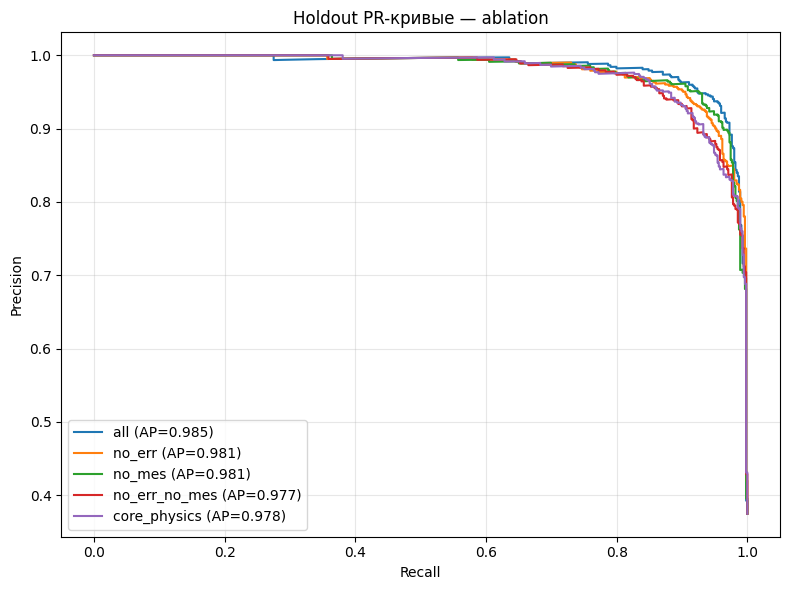

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, r in results.items():
    p, rr, _ = precision_recall_curve(y_test, r["test_preds"])
    ap = average_precision_score(y_test, r["test_preds"])
    ax.plot(rr, p, label=f"{name} (AP={ap:.3f})")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Holdout PR-кривые — ablation")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Сравнение feature importance

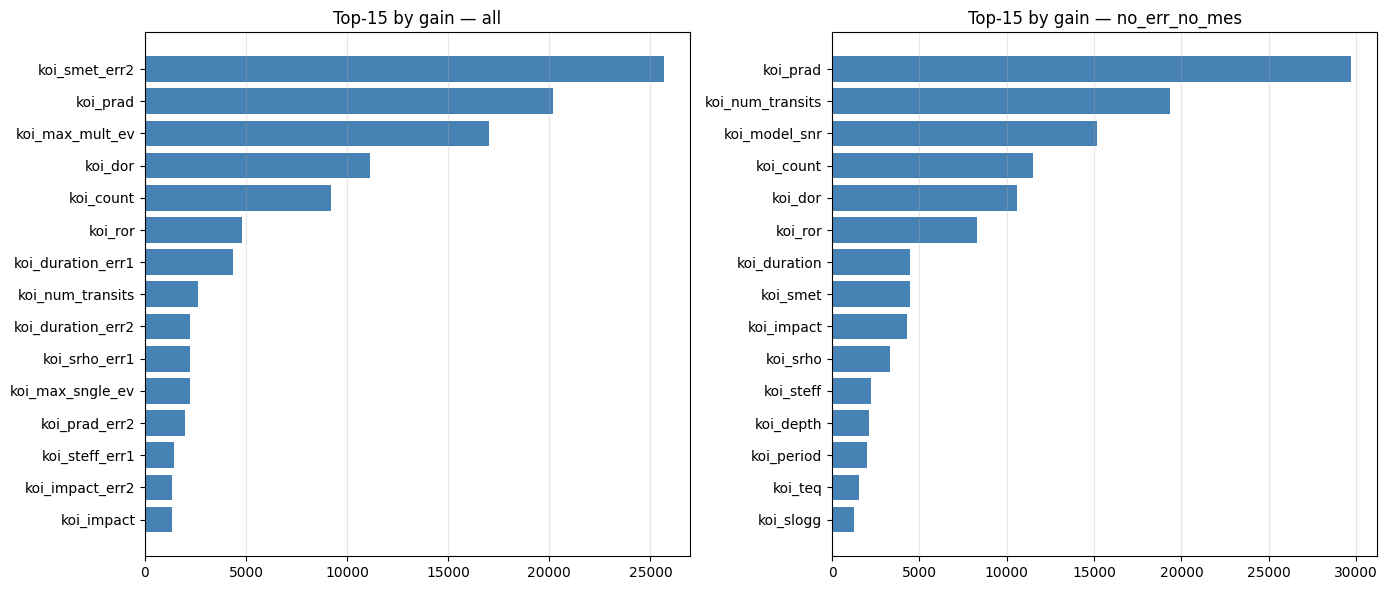

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["all", "no_err_no_mes"]):
    fi = results[name]["feature_importance"].head(15)
    ax.barh(fi["feature"][::-1], fi["gain"][::-1], color="steelblue")
    ax.set_title(f"Top-15 by gain — {name}")
    ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

### Сохранение артефактов

In [11]:
for name, r in results.items():
    pd.DataFrame({
        "train_local_idx": np.arange(len(X_train)),
        "kepid": groups.iloc[train_idx].values,
        "y_true": y_train.values,
        "oof_pred": r["oof_preds"],
    }).to_csv(ABLATION_DIR / f"{name}_oof.csv", index=False)

    pd.DataFrame({
        "test_local_idx": np.arange(len(X_test)),
        "kepid": groups.iloc[test_idx].values,
        "y_true": y_test.values,
        "pred": r["test_preds"],
    }).to_csv(ABLATION_DIR / f"{name}_test.csv", index=False)

    r["feature_importance"].to_csv(ABLATION_DIR / f"{name}_importance.csv", index=False)
    joblib.dump(r["final_model"], ABLATION_DIR / f"{name}_model.pkl")

print(f"Сохранено {len(results)} наборов в {ABLATION_DIR.resolve()}")

Сохранено 5 наборов в C:\Users\Vladislav\.vscode\ML\exoplanet-detector\data\physical_signs_final\ablation


### Вывод по ноутбуку
После удаления всех параметров, что попадали под подозрение на утечку, результат модели почти не изменился -> **начальная гипотеза ноутбука отвергается.**

На данный момент разработки *требуются дополнительные проверки метрик и релевантности полученного результата.*